# COMP9414 Assignment 1 — Search and planning
**Student:** z5615327 · **Term:** 3, 2026

The route-finding and equipment-servicing problems are separate models.
Written answers follow Parts A–D; a reusable evaluation cell at the end reloads
the inputs, runs all 24 required case/algorithm combinations and writes
`z5615327_results.json`. Run with Python 3.11+ and Matplotlib, with `data/` beside
this notebook. The solvers and JSON loading use only the standard library.
All numeric rounding below is for display only.

In [ ]:
import copy   # copy data
import json  # json->python
from pathlib import Path

STUDENT_ID = 'z5615327'    # output filename
DATA_DIR = Path('data')   # work dictionary
# Change input files here; neither solver depends on filenames.
INPUT_FILES = {
    'graphs': {
        'workshop': 'graphs/workshop.json',
        'routes': 'graphs/routes.json',
        'detour': 'graphs/detour.json',
    },
    'planning': {
        'service': 'planning/service.json',
        'ready': 'planning/ready.json',
        'offline': 'planning/offline.json',
    },
}
ALGORITHMS = ('dfs', 'bfs', 'ucs', 'astar')

# json -> memory
def load_inputs():
    return {
        kind: {case: json.loads((DATA_DIR / filename).read_text())
               for case, filename in files.items()}
        for kind, files in INPUT_FILES.items()
    }

# text-print func
def print_table(headers, rows):
    rows = [[str(value) for value in row] for row in rows]
    widths = [max(len(str(header)), *(len(row[i]) for row in rows))
              for i, header in enumerate(headers)]
    def line(row):
        return ' | '.join(str(value).ljust(width)
                          for value, width in zip(row, widths))
    print(line(headers))
    print('-+-'.join('-' * width for width in widths))
    for row in rows:
        print(line(row))

# extract metrics from results
def graph_summary(results):
    rows = []
    for case, runs in results.items():
        for algorithm, r in runs.items():
            cost = None if r['cost'] is None else round(r['cost'], 6)
            edges = len(r['path']) - 1 if r['status'] == 'found' else None
            rows.append([case, algorithm, r['status'], cost, edges,
                         r['expanded_count'], r['generated_count'],
                         r['frontier_peak']])
    print_table(['Case', 'Algorithm', 'Status', 'Cost', 'Edges',
                 'Expanded', 'Generated', 'Frontier peak'], rows)


inputs = load_inputs()    # python dictionary data

## Part A — Problem formulation and hand search traces

### A1. Route-finding formulation

- **States:** the robot's current node identifier in the workshop graph.
- **Initial state:** `depot`.
- **Actions:** from a node, traverse one of its incident edges to its neighbour.
  Edges are undirected, so either direction is allowed.
- **Transition:** traversing `(u, v)` from `u` changes the state to `v`.
- **Goal test:** the current node is `test_bay`.
- **Path cost:** the sum of the stored edge costs along the route; the initial
  path has cost zero. The number of edges is a separate quantity.

### A2. Hand traces: first three expansions

The frontier lists below are ordered **next to pop first**. An entry `path (g)`
contains the complete path and cumulative cost. The abbreviations are
`D=depot`, `A=aisle`, `S=stores`, `R=ramp`, `W=workshop`, `L=lift`,
`T=test_bay`; all comparisons use the full original node names.

| Step | DFS frontier |
|---|---|
| Initial | `D (0)` |
| Expand D | `D→A (2)`; `D→S (2)` |
| Expand A | `D→A→R (5)`; `D→A→W (8)`; `D→S (2)` |
| Expand R | `D→A→R→L (7)`; `D→A→W (8)`; `D→S (2)` |

DFS marks nodes on insertion. From `depot`, it pushes `stores` then `aisle`;
from `aisle`, it pushes `workshop` then `ramp`. At `ramp`, `stores` is already
discovered even though it has not been expanded, so only `lift` is added.

| Step | BFS frontier |
|---|---|
| Initial | `D (0)` |
| Expand D | `D→A (2)`; `D→S (2)` |
| Expand A | `D→S (2)`; `D→A→R (5)`; `D→A→W (8)` |
| Expand S | `D→A→R (5)`; `D→A→W (8)` |

BFS appends neighbours alphabetically. At `stores`, `depot` and `ramp` are
already discovered; BFS retains the earlier path to `ramp` even though its
cost is higher, because BFS does not optimise weighted cost.

| Step | UCS frontier |
|---|---|
| Initial | `D (0)` |
| Expand D | `D→A (2)`; `D→S (2)` |
| Expand A | `D→S (2)`; `D→A→R (5)`; `D→A→W (8)` |
| Expand S | `D→S→R (3)`; `D→A→R (5)` **stale**; `D→A→W (8)` |

The first cost tie is resolved by the full path: `('depot', 'aisle')` precedes
`('depot', 'stores')`. After expanding `stores`, the best cost of `ramp`
changes from 5 to 3. The old cost-5 entry stays queued but will be skipped.

### A3. Complete results

| Algorithm | Complete expansion order | Returned path | Edges | Cost |
|---|---|---|---:|---:|
| DFS | D, A, R, L, T | D→A→R→L→T | 4 | 11 |
| BFS | D, A, S, R, W, L, T | D→A→W→T | 3 | 11 |
| UCS | D, A, S, R, L, W, T | D→S→R→L→T | 4 | 9 |

DFS follows its stack order without optimising cost or edge count. When it
expands `lift`, `workshop` has already been discovered, so it adds `test_bay`.
BFS returns a route with the fewest edges, but the edge from `aisle` to
`workshop` costs 6. UCS finds the cheaper four-edge route through `stores`.
Stale UCS entries are absent from the expansion order, and the popped goal
is included for every algorithm.

### A4. Search-tree entries versus states

`depot→aisle→ramp` has cost 5, while `depot→stores→ramp` has cost 3.
These are different search-tree entries because they describe different
histories, but both reach the state `ramp`. Available moves and goal status
depend only on that current node. UCS must replace the recorded cost-5 path
with the cost-3 path: retaining the first-discovered route would discard a
cheaper way to reach every continuation from `ramp`, including the route
through `lift` to the goal. The old queue entry can remain physically stored
as long as it is recognised as stale when popped.

## Part B — Graph-search implementation and comparison

### B1. Implementation

DFS uses the right end of a deque as a stack; BFS uses its left end as a
queue. UCS/A* use `heapq`, storing `(priority, complete_path, insertion_id, g)`.
`best[node]` stores `(g, path)` and accepts improvements even after an earlier
expansion. There is no permanent closed set for these priority searches.
The public solver never records diagnostic frontiers unless the separate
tracing helper is explicitly called for the written analysis.

DFS/BFS insert each node once. Positive costs ensure that revisiting a node
through a cycle cannot improve its cost; a finite graph has only finitely
many simple paths, so the priority searches terminate too. A* uses the
straight-line distance defined in Part C. UCS never needs coordinates.

In [ ]:
from collections import deque     # dfs bfs
from itertools import count    # insertion_id
import heapq     # ucs astar
import math

#search tool define

# which item take from frontier
# discover a new route, add to frontier or not

def _graph_parts(problem):
    """Build an undirected adjacency list without changing the input."""
    nodes = {node['id']: node for node in problem['nodes']}
    adjacency = {name: [] for name in nodes}
    for edge in problem['edges']:
        u, v, cost = edge['u'], edge['v'], edge['cost']
        adjacency[u].append((v, cost))
        adjacency[v].append((u, cost))
    for neighbours in adjacency.values():
        neighbours.sort(key=lambda item: item[0])
    return nodes, adjacency


def _graph_search(problem, algorithm, trace=None):
    """The optional trace records frontier choices for written explanations."""
    expanded = []    # valid order for expanded nodes
    generated = 0
    peak = 1     # The maximum number of entries that the frontier has ever held.

    def result(status, path=(), cost=None, message=None):
        answer = dict(status=status, path=list(path), cost=cost,
                      expanded_order=expanded, expanded_count=len(expanded),
                      generated_count=generated, frontier_peak=peak)
        if message is not None:
            answer['message'] = message
        return answer

    if algorithm not in ('dfs', 'bfs', 'ucs', 'astar'):
        peak = 0
        return result('error', message='Use dfs, bfs, ucs, or astar.')

    nodes, adjacency = _graph_parts(problem)
    start, goal = problem['start'], problem['goal']

    def h(node):
        # UCS does not access coordinates in its priority calculation.
        if algorithm != 'astar':
            return 0
        return math.hypot(nodes[node]['x'] - nodes[goal]['x'],
                          nodes[node]['y'] - nodes[goal]['y'])

    priority_search = algorithm in ('ucs', 'astar')
    serial = count()
    if priority_search:
        # Fields enforce priority, complete path, then insertion order.
        frontier = [(h(start), (start,), next(serial), 0)]
        best = {start: (0, (start,))}
    else:
        frontier = deque([((start,), 0)])
        discovered = {start}

    def snapshot():        # used for part C
        if priority_search:
            return [dict(path=list(path), g=g, priority=priority,
                         stale=(g, path) != best[path[-1]])
                    for priority, path, _, g in sorted(frontier)]
        entries = list(frontier)
        if algorithm == 'dfs':
            entries.reverse()
        return [dict(path=list(path), g=g, stale=False) for path, g in entries]

    while frontier:
        before = snapshot() if trace is not None else None
        if priority_search:
            _, path, _, g = heapq.heappop(frontier)
            if (g, path) != best[path[-1]]:
                continue  # Stale entries do not count as expansions.
        elif algorithm == 'dfs':
            path, g = frontier.pop()
        else:
            path, g = frontier.popleft()

        node = path[-1]
        expanded.append(node)
        if node == goal:
            if trace is not None:
                trace.append(dict(node=node, before=before, after=snapshot()))
            return result('found', path, g)

        # Candidates are counted before discovery or best-path filtering.
        neighbours = adjacency[node]
        generated += len(neighbours)
        if algorithm == 'dfs':
            neighbours = reversed(neighbours)
        for neighbour, edge_cost in neighbours:
            new_path = path + (neighbour,)
            new_g = g + edge_cost
            if priority_search:
                pair = (new_g, new_path)
                if neighbour not in best or pair < best[neighbour]:
                    best[neighbour] = pair
                    heapq.heappush(frontier, (new_g + h(neighbour), new_path,
                                             next(serial), new_g))
            elif neighbour not in discovered:
                discovered.add(neighbour)
                frontier.append((new_path, new_g))
            peak = max(peak, len(frontier))
        if trace is not None:
            trace.append(dict(node=node, before=before, after=snapshot()))

    return result('not_found')


def solve_graph(problem: dict, algorithm: str) -> dict:
    """Return a deterministic DFS, BFS, UCS, or A* graph-search result."""
    return _graph_search(problem, algorithm)

### B2. Three-map comparison

The summary includes status, cost, path edge count and all three effort
metrics. Full paths and expansion orders follow the table; the reusable
evaluation cell also saves them without rounding.

In [5]:
graph_runs = {
    case: {algorithm: solve_graph(problem, algorithm) for algorithm in ALGORITHMS}
    for case, problem in inputs['graphs'].items()
}
graph_summary(graph_runs)
for case, runs in graph_runs.items():
    for algorithm, result in runs.items():
        print(f'\n{case} / {algorithm}')
        print('Path:', ' -> '.join(result['path']))
        print('Expanded:', ', '.join(result['expanded_order']))

Case     | Algorithm | Status | Cost  | Edges | Expanded | Generated | Frontier peak
---------+-----------+--------+-------+-------+----------+-----------+--------------
workshop | dfs       | found  | 11    | 4     | 5        | 11        | 3            
workshop | bfs       | found  | 11    | 3     | 7        | 16        | 3            
workshop | ucs       | found  | 9     | 4     | 7        | 16        | 3            
workshop | astar     | found  | 9     | 4     | 6        | 13        | 4            
routes   | dfs       | found  | 1.143 | 4     | 14       | 52        | 8            
routes   | bfs       | found  | 1.143 | 4     | 17       | 65        | 7            
routes   | ucs       | found  | 0.905 | 4     | 18       | 70        | 6            
routes   | astar     | found  | 0.905 | 4     | 7        | 27        | 9            
detour   | dfs       | found  | 11    | 3     | 6        | 12        | 3            
detour   | bfs       | found  | 11    | 3     | 7        | 14    

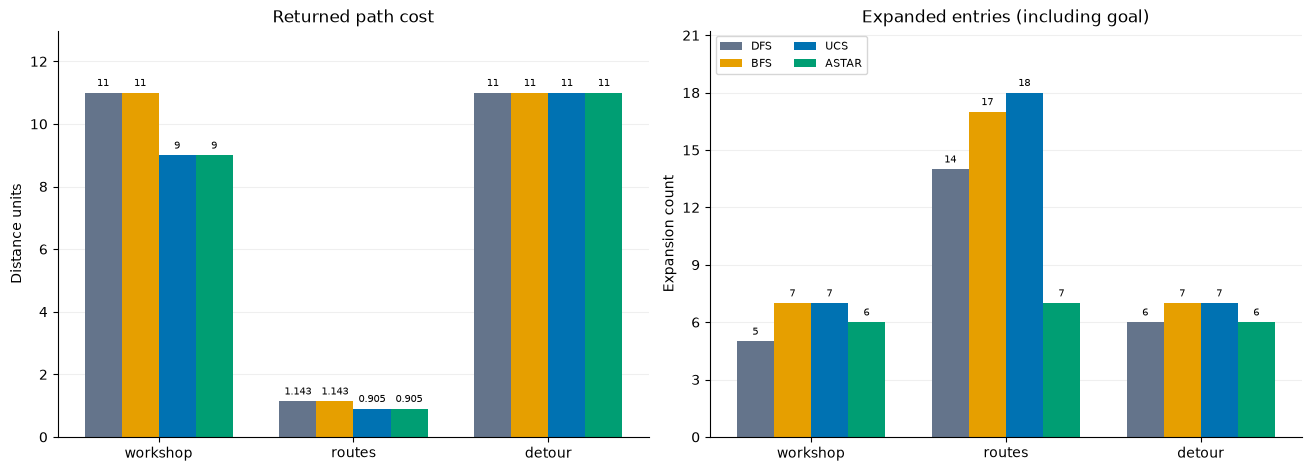

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

cases = list(graph_runs)
colours = ['#64748b', '#e69f00', '#0072b2', '#009e73']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
width = 0.19
for i, algorithm in enumerate(ALGORITHMS):
    positions = [x + (i - 1.5) * width for x in range(len(cases))]
    for ax, metric in zip(axes, ['cost', 'expanded_count']):
        values = [graph_runs[case][algorithm][metric] for case in cases]
        bars = ax.bar(positions, values, width, label=algorithm.upper(),
                      color=colours[i])
        labels = [f'{value:.3f}'.rstrip('0').rstrip('.') for value in values]
        ax.bar_label(bars, labels=labels, fontsize=7.5, padding=3)
for ax in axes:
    ax.set_xticks(range(len(cases)), cases)
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.2)
    ax.spines[['top', 'right']].set_visible(False)
    ax.margins(y=0.18)
axes[0].set(title='Returned path cost', ylabel='Distance units')
axes[1].set(title='Expanded entries (including goal)', ylabel='Expansion count')
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].legend(ncol=2, fontsize=8, loc='upper left')
plt.show()

#axes[0] left.  axes[1] right

Removing `ramp–lift` raises the cheapest route's cost from **9 to 11**.
UCS changes from `depot→stores→ramp→lift→test_bay` (four edges) to
`depot→aisle→workshop→test_bay` (three edges). Thus the closed map's cheapest
route has fewer edges but greater cost. The original BFS route also shows
this distinction: three edges cost 11, while UCS's four edges cost 9.

The closure does not uniformly increase effort. DFS expansions rise from
5 to 6 and generated candidates from 11 to 12. BFS and UCS each still expand
7 entries, but generated candidates fall from 16 to 14 because the removed
edge no longer contributes either direction. A* still expands 6 entries;
its generated count falls from 13 to 12 and frontier peak from 4 to 3.
DFS, BFS and UCS have peak 3 in both maps. Search effort depends on frontier
order, topology and stopping time, not simply on the returned route's cost.

On `routes`, DFS and BFS return cost 1.143, while UCS and A* return 0.905.
DFS expands 14 entries, BFS 17, UCS 18 and A* 7. Therefore fewer expansions
alone do not establish a lower-cost solution.

### B3. Small checks and metric conventions

Each modification uses its own deep copy. At the initial goal, every
algorithm must return the one-node path, zero cost, one expansion, zero
generated candidates and frontier peak one. For the isolated goal, all
four must exhaust their frontier and return `not_found`, an empty path and
`None` cost; stale priority entries do not count as expansions.
For the supplied isolated-goal copy, all four expand the six reachable
nodes and generate 14 candidates: each of the seven remaining undirected
edges is considered from both ends. Each has frontier peak 3.

In [ ]:
def derived_graphs(graphs):
    at_goal = copy.deepcopy(graphs['workshop'])
    at_goal['goal'] = at_goal['start']
    isolated = copy.deepcopy(graphs['workshop'])
    goal = isolated['goal']
    isolated['edges'] = [edge for edge in isolated['edges']
                         if goal not in (edge['u'], edge['v'])]
    zero = copy.deepcopy(graphs['routes'])å
    for node in zero['nodes']:
        node['x'] = node['y'] = 0
    return {'at_goal': at_goal, 'isolated_goal': isolated, 'zero_coordinates': zero}


derived = derived_graphs(inputs['graphs'])
check_runs = {
    case: {a: solve_graph(derived[case], a) for a in ALGORITHMS}
    for case in ('at_goal', 'isolated_goal')
}
graph_summary(check_runs)
for algorithm in ALGORITHMS:
    r = check_runs['at_goal'][algorithm]
    assert r == dict(status='found', path=[derived['at_goal']['start']], cost=0,
                     expanded_order=[derived['at_goal']['start']], expanded_count=1,
                     generated_count=0, frontier_peak=1)
    r = check_runs['isolated_goal'][algorithm]
    assert r['status'] == 'not_found' and r['path'] == [] and r['cost'] is None
    assert r['expanded_count'] == len(r['expanded_order'])
    assert derived['isolated_goal']['goal'] not in r['expanded_order']
print('Both boundary checks passed for all four algorithms.')

Case          | Algorithm | Status    | Cost | Edges | Expanded | Generated | Frontier peak
--------------+-----------+-----------+------+-------+----------+-----------+--------------
at_goal       | dfs       | found     | 0    | 0     | 1        | 0         | 1            
at_goal       | bfs       | found     | 0    | 0     | 1        | 0         | 1            
at_goal       | ucs       | found     | 0    | 0     | 1        | 0         | 1            
at_goal       | astar     | found     | 0    | 0     | 1        | 0         | 1            
isolated_goal | dfs       | not_found | None | None  | 6        | 14        | 3            
isolated_goal | bfs       | not_found | None | None  | 6        | 14        | 3            
isolated_goal | ucs       | not_found | None | None  | 6        | 14        | 3            
isolated_goal | astar     | not_found | None | None  | 6        | 14        | 3            
Both boundary checks passed for all four algorithms.


## Part C — A* heuristic behaviour

### C1. Straight-line heuristic

$$h(n)=\sqrt{(x_n-x_g)^2+(y_n-y_g)^2},\qquad f(n)=g(n)+h(n).$$

The implementation uses `math.hypot`. Coordinates estimate remaining cost;
the actual accumulated cost always comes from the edge records. UCS uses
only $g$. Neither algorithm rounds values before comparison.

### C2. Metrics and the first different expansion

| Graph | Algorithm | Cost | Expanded | Generated | Frontier peak |
|---|---|---:|---:|---:|---:|
| workshop | UCS | 9 | 7 | 16 | 3 |
| workshop | A* | 9 | 6 | 13 | 4 |
| routes | UCS | 0.905 | 18 | 70 | 6 |
| routes | A* | 0.905 | 7 | 27 | 9 |

On **workshop**, both first expand `depot, aisle, stores, ramp, lift`.
Their sixth expansion differs. The two current competing paths are:

| Path | g | h | g+h |
|---|---:|---:|---:|
| depot→stores→ramp→lift→workshop | 7 | 2 | 9 |
| depot→stores→ramp→lift→test_bay | 9 | 0 | 9 |

UCS chooses `workshop` because 7 < 9. A* sees an $f=9$ tie and chooses
`test_bay`, since its full path is lexicographically smaller: the first
different strings are `test_bay` and `workshop`. There are also stale
entries, listed in the diagnostic output below. They affect queue size,
but cannot become counted expansions.

On **routes**, the first difference is expansion 2, immediately after `S`:

| Path | g | h (display rounded) | g+h (display rounded) |
|---|---:|---:|---:|
| S→C | 0.168 | 0.701902 | 0.869902 |
| S→I | 0.222 | 0.712261 | 0.934261 |
| S→M | 0.225 | 0.607117 | 0.832117 |
| S→H | 0.307 | 0.625105 | 0.932105 |

UCS chooses `C` for its smallest $g$; A* chooses `M` for its smallest $g+h$.
The heuristic reduces expanded/generated entries on both graphs, while
**increasing frontier peak**. A* can retain branches and stale entries while
following a promising route and stopping earlier. In particular, workshop
A* still holds the stale path to `ramp` when it reaches the goal, whereas
UCS has already discarded it. Lower total expansion work does not imply a
smaller maximum queue.

The next cell records the actual frontier immediately before each first
different choice, in removal order. Stale entries are explicitly labelled.

In [8]:
def show_first_difference(problem):
    traces = {}
    for algorithm in ('ucs', 'astar'):
        events = []
        _graph_search(problem, algorithm, trace=events)
        traces[algorithm] = events
    nodes = {n['id']: n for n in problem['nodes']}
    goal = nodes[problem['goal']]
    for index, (u_event, a_event) in enumerate(zip(traces['ucs'], traces['astar']), 1):
        if u_event['node'] == a_event['node']:
            continue
        print(f'First different expansion: {index}')
        for algorithm, event in [('ucs', u_event), ('astar', a_event)]:
            print(f"{algorithm.upper()} chooses {event['node']}")
            rows = []
            for entry in event['before']:
                node = nodes[entry['path'][-1]]
                h = math.hypot(node['x'] - goal['x'], node['y'] - goal['y'])
                g = entry['g']
                rows.append([' -> '.join(entry['path']), f'{g:.6f}',
                             f'{h:.6f}', f'{g+h:.6f}',
                             'stale' if entry['stale'] else 'current'])
            print_table(['Path (next pop first)', 'g', 'h', 'g+h', 'Entry'], rows)
        return
    print('No differing expansion in the common prefix.')


for case in ('workshop', 'routes'):
    print('\n' + case)
    show_first_difference(inputs['graphs'][case])


workshop
First different expansion: 6
UCS chooses workshop
Path (next pop first)                       | g        | h        | g+h       | Entry  
--------------------------------------------+----------+----------+-----------+--------
depot -> stores -> ramp -> lift -> workshop | 7.000000 | 2.000000 | 9.000000  | current
depot -> aisle -> workshop                  | 8.000000 | 2.000000 | 10.000000 | stale  
depot -> stores -> ramp -> lift -> test_bay | 9.000000 | 0.000000 | 9.000000  | current
ASTAR chooses test_bay
Path (next pop first)                       | g        | h        | g+h       | Entry  
--------------------------------------------+----------+----------+-----------+--------
depot -> stores -> ramp -> lift -> test_bay | 9.000000 | 0.000000 | 9.000000  | current
depot -> stores -> ramp -> lift -> workshop | 7.000000 | 2.000000 | 9.000000  | current
depot -> aisle -> ramp                      | 5.000000 | 4.472136 | 9.472136  | stale  
depot -> aisle -> workshop           

### C3. Removing coordinate information

After setting every coordinate to `(0, 0)`, $h(n)=0$ for all nodes, including
the goal. A* priorities are then exactly $g(n)$, so the same complete-path
and insertion tie-breaking makes the returned path, expansion order and
all metrics match UCS. The following assertion checks the entire result.

For this case, cost remains 0.905, expansions rise from the original A*'s
7 to 18, generated candidates rise from 27 to 70, and frontier peak falls
from 9 to 6. Thus the coordinates were useful even though their use did not
reduce every metric.

Straight-line distance can give little guidance when a node is physically
near the goal but a missing connection or obstacle forces a long detour.
The coordinates do not reveal that missing connection. In `detour`, for
example, `ramp` still has the same straight-line estimate after `ramp–lift`
is removed, although reaching the goal now requires going back through
`aisle` and `workshop`.

In [9]:
zero_result = solve_graph(derived['zero_coordinates'], 'astar')
assert zero_result == graph_runs['routes']['ucs']
print('Zero-coordinate A* exactly matches the full UCS result.')
print(json.dumps(zero_result, indent=2))

Zero-coordinate A* exactly matches the full UCS result.
{
  "status": "found",
  "path": [
    "S",
    "M",
    "K",
    "Q",
    "G"
  ],
  "cost": 0.905,
  "expanded_order": [
    "S",
    "C",
    "I",
    "M",
    "H",
    "K",
    "R",
    "F",
    "E",
    "B",
    "D",
    "O",
    "J",
    "N",
    "Q",
    "L",
    "A",
    "G"
  ],
  "expanded_count": 18,
  "generated_count": 70,
  "frontier_peak": 6
}


## Part D — STRIPS modelling and forward BFS planning

### D1. Action sets

| Action | Preconditions | Add | Delete |
|---|---|---|---|
| `service(camera)` | `on_bench(camera)`, `needs_service(camera)`, `tool_ready` | `serviced(camera)`, `tool_used` | `needs_service(camera)`, `tool_ready` |
| `reset_tool()` | `bench_free`, `tool_used` | `tool_ready` | `tool_used` |

Each cell lists a set. Actions apply only when all preconditions hold; all
facts outside the add/delete effects remain unchanged.

### D2. Diagnose and repair the proposed plan

The first inapplicable action is step 4, `reset_tool()`. After mounting,
servicing and testing the camera, the complete state is:

```text
{
  needs_service(sensor),
  on_bench(camera),
  on_rack(sensor),
  serviced(camera),
  tested(camera),
  tool_used,
  untested(sensor)
}
```

The **only missing precondition is `bench_free`**. `tool_used` is present,
but the tested camera is still on the bench. Testing does not store it.

If the reset is omitted, storing the camera and mounting the sensor are
applicable. The next `service(sensor)` then fails because `tool_ready` is
absent. This is original step 7, or step 6 in the shortened sequence.
Mounting the sensor has also consumed `bench_free`, so resetting at that
point would not be applicable either.

A repaired plan moves the reset to immediately after storing the camera:

1. `mount(camera)`
2. `service(camera)`
3. `test(camera)`
4. `store(camera)`
5. `reset_tool()`
6. `mount(sensor)`
7. `service(sensor)`
8. `test(sensor)`
9. `store(sensor)`

The final state is `{bench_free, on_rack(camera), on_rack(sensor),
serviced(camera), serviced(sensor), tested(camera), tested(sensor), tool_used}`.
It contains all five goal facts: both `tested` facts, both `on_rack` facts,
and `bench_free`. The goal does not require `tool_ready`.

### D3. Generic forward BFS planner

States are immutable fact sets, so permutations of facts are equal states.
Actions are sorted by their full name and read directly from JSON, without
parsing equipment names. The transition is $(s-Del(a))\cup Add(a)$;
the goal test is set inclusion. Discovery happens on insertion into the
queue. Unit action costs mean that BFS's first popped goal has a minimum
action count. The finite set of input facts gives a finite state space.

In [ ]:
def solve_planning(problem: dict) -> dict:
    """Forward BFS on fact sets, using only the supplied action records."""
    initial = frozenset(problem['initial'])
    goal = frozenset(problem['goal'])
    actions = [(action['name'], frozenset(action['preconditions']),
                frozenset(action['add']), frozenset(action['delete']))
               for action in sorted(problem['actions'], key=lambda a: a['name'])]

    # initial bfs
    frontier = deque([(initial, ())])
    discovered = {initial}
    expanded = []
    generated = 0
    peak = 1

    def result(status, plan=(), cost=None):
        return dict(status=status, plan=list(plan), cost=cost,
                    expanded_order=expanded, expanded_count=len(expanded),
                    generated_count=generated, frontier_peak=peak)
    # bfs loop
    while frontier:
        state, plan = frontier.popleft()
        expanded.append(sorted(state))
        if goal <= state:
            return result('found', plan, len(plan))
        for name, preconditions, add, delete in actions:
            if preconditions <= state:
                generated += 1
                successor = (state - delete) | add     # STRIPS formula
                if successor not in discovered:
                    discovered.add(successor)
                    frontier.append((successor, plan + (name,)))
                    peak = max(peak, len(frontier))
    return result('not_found')

In [11]:
def planning_summary(results):
    print_table(['Case', 'Status', 'Plan length', 'Expanded', 'Generated', 'Frontier peak'],
                [[case, r['status'], r['cost'], r['expanded_count'],
                  r['generated_count'], r['frontier_peak']]
                 for case, r in results.items()])
    for case, r in results.items():
        print(f'\n{case} plan:', ' -> '.join(r['plan']) or '[]')


planning_runs = {case: solve_planning(problem)
                 for case, problem in inputs['planning'].items()}
planning_summary(planning_runs)

Case    | Status    | Plan length | Expanded | Generated | Frontier peak
--------+-----------+-------------+----------+-----------+--------------
service | found     | 9           | 22       | 26        | 4            
ready   | found     | 7           | 17       | 21        | 4            
offline | not_found | None        | 11       | 12        | 2            

service plan: mount(camera) -> service(camera) -> test(camera) -> store(camera) -> reset_tool() -> mount(sensor) -> service(sensor) -> test(sensor) -> store(sensor)

ready plan: mount(camera) -> test(camera) -> store(camera) -> mount(sensor) -> service(sensor) -> test(sensor) -> store(sensor)

offline plan: []


### D4. Variants and a modelling fault

The baseline **service** case returns the repaired nine-action plan above,
with 22 expanded states, 26 generated candidates and frontier peak 4.
Each unit requires mount, service, test and store; both need the tool,
requiring one reset between their services. This gives a lower bound of
$4+4+1=9$ actions, attained by the returned plan.

In **ready**, the camera needs only mount, test and store. The sensor needs
four actions, and its service is the only use of the initially ready tool.
No reset is necessary, giving a minimum of $3+4=7$ actions. BFS expands
17 states and generates 21 candidates, both fewer than baseline, while
frontier peak remains 4. The changed initial facts remove the need for two
actions and change the reachable state space; effort is not determined by
plan length alone.

In **offline**, the result is `not_found`, with no plan and `None` cost.
BFS exhausts 11 states, generates 12 candidates and has peak 2. After the
first service, `tool_ready` is removed and `tool_used` is added. Only
`reset_tool()` could restore `tool_ready`, but it is unavailable. Both
units initially need service, so the second cannot become serviced or
tested. Fewer expansions here reflect a smaller exhausted state space,
not a more efficient successful plan.

If `mount(u)` fails to delete `bench_free`, the faulty model allows
`mount(camera), mount(sensor)` from the baseline initial state. After the
first mount, `bench_free` incorrectly remains true, allowing the second
mount and leaving both units on a one-unit bench. The missing delete
effect is `bench_free` on every mount action. Changing BFS tie-breaking
only changes exploration order; it does not change the incorrect
applicability and transition rules. The action model must be repaired.

## Reusable evaluation cell — all required cases

This cell is independent of the earlier experimental result variables.
After the function definitions have run, rerun it to reload all filenames
from `INPUT_FILES`, create fresh derived copies, call both public solvers,
display summaries and all paths/plans/expansion orders, and save complete
unrounded returned fields. Labels are distinct for each case and algorithm.

The 24 runs are 12 supplied-map runs, 8 boundary checks, 1 zero-coordinate
A* run and 3 planning runs. No wall-clock timing is required. Expanded
counts include the initial and popped goal entries, generated counts are
before duplicate filtering, and peak counts include queued stale entries.

In [12]:
# REUSABLE EVALUATION CELL: input filenames are all in INPUT_FILES above.
evaluation_inputs = load_inputs()
evaluation_copies = derived_graphs(evaluation_inputs['graphs'])
evaluation_graphs = {
    **evaluation_inputs['graphs'],
    'at_goal': evaluation_copies['at_goal'],
    'isolated_goal': evaluation_copies['isolated_goal'],
}
results = {
    'graphs': {
        case: {algorithm: solve_graph(problem, algorithm) for algorithm in ALGORITHMS}
        for case, problem in evaluation_graphs.items()
    },
    'planning': {
        case: solve_planning(problem)
        for case, problem in evaluation_inputs['planning'].items()
    },
}
results['graphs']['zero_coordinates'] = {
    'astar': solve_graph(evaluation_copies['zero_coordinates'], 'astar')
}

print('GRAPH RESULTS')
graph_summary(results['graphs'])
print('\nPLANNING RESULTS')
planning_summary(results['planning'])

for case, runs in results['graphs'].items():
    for algorithm, r in runs.items():
        print(f'\n{case} / {algorithm} | path={r["path"]}')
        print('expanded_order =', r['expanded_order'])
for case, r in results['planning'].items():
    print(f'\n{case} | plan={r["plan"]}')
    print('expanded_order (one sorted fact set per line):')
    for index, state in enumerate(r['expanded_order'], 1):
        print(f'  {index}: {state}')

for algorithm in ALGORITHMS:
    r = results['graphs']['at_goal'][algorithm]
    start = evaluation_copies['at_goal']['start']
    assert r == dict(status='found', path=[start], cost=0, expanded_order=[start],
                     expanded_count=1, generated_count=0, frontier_peak=1)
    r = results['graphs']['isolated_goal'][algorithm]
    assert (r['status'], r['path'], r['cost']) == ('not_found', [], None)
assert results['graphs']['zero_coordinates']['astar'] == results['graphs']['routes']['ucs']
run_count = sum(len(runs) for runs in results['graphs'].values()) + len(results['planning'])
assert run_count == 24
output_path = Path(f'{STUDENT_ID}_results.json')
output_path.write_text(json.dumps(results, indent=2, allow_nan=False) + '\n')
print(f'\nSaved all {run_count} full results to {output_path}. Checks passed.')

GRAPH RESULTS
Case             | Algorithm | Status    | Cost  | Edges | Expanded | Generated | Frontier peak
-----------------+-----------+-----------+-------+-------+----------+-----------+--------------
workshop         | dfs       | found     | 11    | 4     | 5        | 11        | 3            
workshop         | bfs       | found     | 11    | 3     | 7        | 16        | 3            
workshop         | ucs       | found     | 9     | 4     | 7        | 16        | 3            
workshop         | astar     | found     | 9     | 4     | 6        | 13        | 4            
routes           | dfs       | found     | 1.143 | 4     | 14       | 52        | 8            
routes           | bfs       | found     | 1.143 | 4     | 17       | 65        | 7            
routes           | ucs       | found     | 0.905 | 4     | 18       | 70        | 6            
routes           | astar     | found     | 0.905 | 4     | 7        | 27        | 9            
detour           | dfs    

## References and reproducibility

- COMP9414 Assignment 1, *Search and planning for an equipment service robot*,
  Term 3, 2026: interfaces, ordering, metrics, problem descriptions and tasks.
- Supplied Term 3 JSON data and `data/manifest.json`: graph and planning instances.

The submission archive contains this executed notebook and its generated
JSON results. The figure is embedded in the notebook. The supplied `data/`
folder is kept unchanged and is provided separately during marking.